# 01 — The stellar initial mass function (IMF)

*Galaxies course, Masaryk University — Lecture 1: stellar populations and the IMF*

The IMF $\xi(m) = dN/dm$ tells us how many stars are born per unit mass interval. We write it as (multi-)power laws
$\xi(m) \propto m^{-\alpha}$:

| IMF | slopes |
|---|---|
| Salpeter (1955) | $\alpha = 2.35$ for all masses |
| Kroupa (2001) | $\alpha_1 = 1.3$ for $0.08$–$0.5\,M_\odot$, $\alpha_2 = 2.3$ above |

Remember: the IMF is not observed directly. It is a statistical construct (a *Hilfskonstrukt*) inferred from star counts after many corrections.

In this notebook you will **draw stars from the IMF**, see where the **number, mass and light** of a population sit, and find out why the **most massive star depends on the size of the cluster**.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # makes the small 'stellarpops' package importable
import numpy as np
import matplotlib.pyplot as plt
from stellarpops.style import use_slide_style
use_slide_style(dark=False, scale=0.7)       # dark=True gives the lecture-slide look

from stellarpops import sample_imf, kroupa_xi, number_fraction, mass_fraction
from stellarpops.imf import powerlaw_imf_xi, KROUPA, SALPETER

## 1. Plot the IMF
Plotting $\xi(m)$ on log–log axes turns power laws into straight lines.

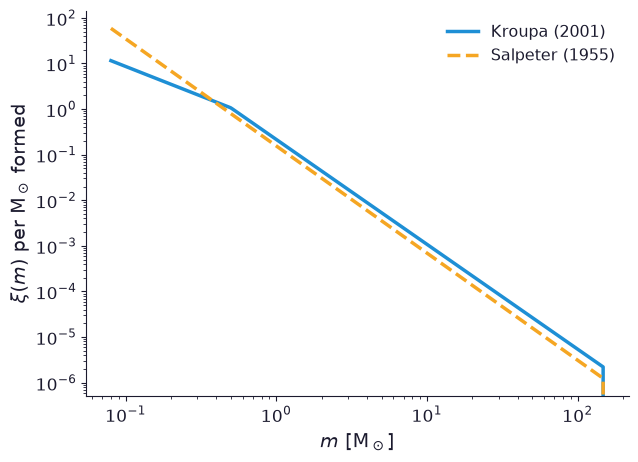

In [2]:
m = np.geomspace(0.08, 150, 500)
xi_k = powerlaw_imf_xi(m, **KROUPA)
xi_s = powerlaw_imf_xi(m, breaks=[0.08, 150], alphas=[2.35])
# normalise both to 1 Msun of stars formed
xi_k /= np.trapezoid(xi_k * m, m); xi_s /= np.trapezoid(xi_s * m, m)

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(m, xi_k, label='Kroupa (2001)')
ax.loglog(m, xi_s, '--', label='Salpeter (1955)')
ax.set_xlabel(r'$m$ [M$_\odot$]'); ax.set_ylabel(r'$\xi(m)$ per M$_\odot$ formed'); ax.legend()

**Question:** where do the two IMFs differ, and by how much? Why was this region the hardest to measure for Salpeter in 1955?

## 2. Draw a star cluster (the dice game, in code)
`sample_imf(N)` draws `N` random stellar masses from the IMF.

In [3]:
rng = np.random.default_rng(1)
for N in [30, 300, 3000, 30000]:
    stars = sample_imf(N, rng=rng)
    print(f"N = {N:6d}:  total mass = {stars.sum():8.1f} Msun,  most massive = {stars.max():6.1f} Msun,  stars > 8 Msun: {(stars > 8).sum()}")

N =     30:  total mass =     12.0 Msun,  most massive =    1.7 Msun,  stars > 8 Msun: 0
N =    300:  total mass =    155.7 Msun,  most massive =   20.1 Msun,  stars > 8 Msun: 2
N =   3000:  total mass =   1724.6 Msun,  most massive =   53.8 Msun,  stars > 8 Msun: 17
N =  30000:  total mass =  17739.1 Msun,  most massive =  115.6 Msun,  stars > 8 Msun: 188


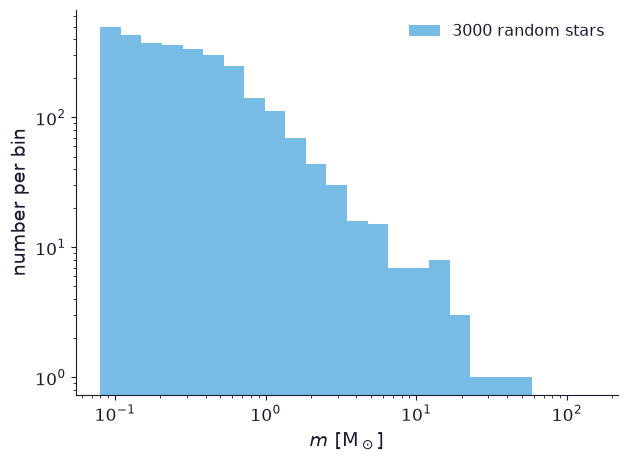

In [4]:
stars = sample_imf(3000, rng=2)
bins = np.geomspace(0.08, 150, 25)
plt.figure(figsize=(7, 5))
plt.hist(stars, bins=bins, histtype='stepfilled', alpha=0.6, label='3000 random stars')
plt.xscale('log'); plt.yscale('log'); plt.xlabel(r'$m$ [M$_\odot$]'); plt.ylabel('number per bin'); plt.legend()

## 3. Where are the stars, the mass and the light?
For a Kroupa IMF at birth (zero-age main sequence). For the light we use a textbook piecewise main-sequence mass–luminosity relation: $L \approx 0.23\,m^{2.3}$ ($m<0.43$), $m^4$ ($0.43$–$2$), $1.4\,m^{3.5}$ ($2$–$55$), $32000\,m$ ($>55$), in solar units — good enough for a feeling, not for research.

 0.08–0.5 Msun:   76.1% of stars,  27.4% of mass,   0.00% of light
    0.5–1 Msun:   14.2% of stars,  16.6% of mass,   0.00% of light
      1–8 Msun:    9.1% of stars,  33.4% of mass,   0.48% of light
    8–150 Msun:    0.6% of stars,  22.6% of mass,  99.52% of light


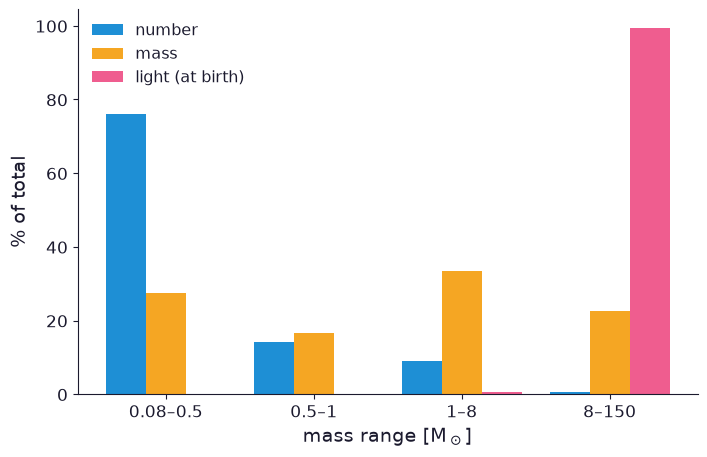

In [5]:
edges = [0.08, 0.5, 1, 8, 150]
labels = ['0.08–0.5', '0.5–1', '1–8', '8–150']
num = [number_fraction(a, b) for a, b in zip(edges[:-1], edges[1:])]
mas = [mass_fraction(a, b) for a, b in zip(edges[:-1], edges[1:])]
mm = np.geomspace(0.08, 150, 4000); w = kroupa_xi(mm)
L = np.where(mm < 0.43, 0.23 * mm**2.3, np.where(mm < 2, mm**4, np.where(mm < 55, 1.4 * mm**3.5, 32000 * mm)))
lum = [np.trapezoid((w * L)[(mm >= a) & (mm < b)], mm[(mm >= a) & (mm < b)]) for a, b in zip(edges[:-1], edges[1:])]
lum = np.array(lum) / np.sum(lum)

x = np.arange(4); fig, ax = plt.subplots(figsize=(8, 5))
for i, (vals, name) in enumerate([(num, 'number'), (mas, 'mass'), (lum, 'light (at birth)')]):
    ax.bar(x + (i - 1) * 0.27, np.array(vals) * 100, width=0.27, label=name)
ax.set_xticks(x, labels); ax.set_xlabel(r'mass range [M$_\odot$]'); ax.set_ylabel('% of total'); ax.legend()
for l, n, s, L in zip(labels, num, mas, lum):
    print(f"{l:>9} Msun:  {100*n:5.1f}% of stars, {100*s:5.1f}% of mass, {100*L:6.2f}% of light")

**Questions**
1. Which stars dominate the *number*, which the *mass*, which the *light*?
2. A galaxy is 10 Gyr old. Stars above ~1 M$_\odot$ have died. Who dominates its light now? (Hint: think of red giants.)
3. Why does this make measuring the low-mass IMF of a distant galaxy so hard?

## 4. Your turn: the most massive star vs the cluster mass
Draw many clusters of different sizes and plot $m_{\max}$ against the cluster mass $M_{\rm cl}$. Is there a relation? (Observed young clusters follow a $m_{\max}$–$M_{\rm cl}$ relation, Weidner & Kroupa 2006 — is pure random sampling enough to explain it? This question is still debated.)

Text(0, 0.5, '$m_{\\max}$ [M$_\\odot$]')

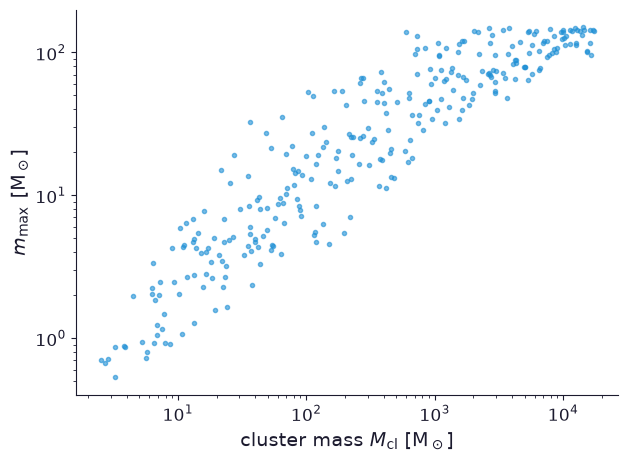

In [6]:
Mcl, mmax = [], []
for N in np.geomspace(10, 30000, 300).astype(int):
    s = sample_imf(N)
    Mcl.append(s.sum()); mmax.append(s.max())
plt.figure(figsize=(7, 5))
plt.loglog(Mcl, mmax, '.', alpha=0.6)
plt.xlabel(r'cluster mass $M_{\rm cl}$ [M$_\odot$]'); plt.ylabel(r'$m_{\max}$ [M$_\odot$]')

**Extra:** change the IMF to a top-heavy one (`kroupa_xi` / `powerlaw_imf_xi` with a flatter high-mass slope, e.g. `alphas=[1.3, 1.9]`) and redo sections 3 and 4. What changes?